<a href="https://colab.research.google.com/github/670710736/projectAI/blob/main/banana.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip -q install kagglehub

import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "shahriar26s/banana-ripeness-classification-dataset"
)

print("Dataset path:", dataset_path)
print("Files:", os.listdir(dataset_path))


100%|██████████| 221M/221M [00:01<00:00, 118MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/shahriar26s/banana-ripeness-classification-dataset/versions/1
Files: ['Banana Ripeness Classification Dataset']


In [ ]:
from pathlib import Path

root = Path(dataset_path) / "Banana Ripeness Classification Dataset"

total_images = 0

for split in ["train", "valid", "test"]:
    folder = root / split

    print(f"\n===== {split.upper()} =====")

    split_total = 0

    for class_folder in sorted(folder.iterdir()):
        if class_folder.is_dir():
            images = [
                p for p in class_folder.rglob("*")
                if p.suffix.lower() in
                [".jpg", ".jpeg", ".png", ".webp"]
            ]

            count = len(images)
            split_total += count

            print(f"{class_folder.name}: {count} images")

    total_images += split_total
    print(f"Total {split}: {split_total} images")

print(f"\nTOTAL DATASET: {total_images} images")


===== TRAIN =====
overripe: 2349 images
ripe: 3522 images
rotten: 4020 images
unripe: 1902 images
Total train: 11793 images

===== VALID =====
overripe: 229 images
ripe: 339 images
rotten: 388 images
unripe: 167 images
Total valid: 1123 images

===== TEST =====
overripe: 113 images
ripe: 154 images
rotten: 185 images
unripe: 110 images
Total test: 562 images

TOTAL DATASET: 13478 images


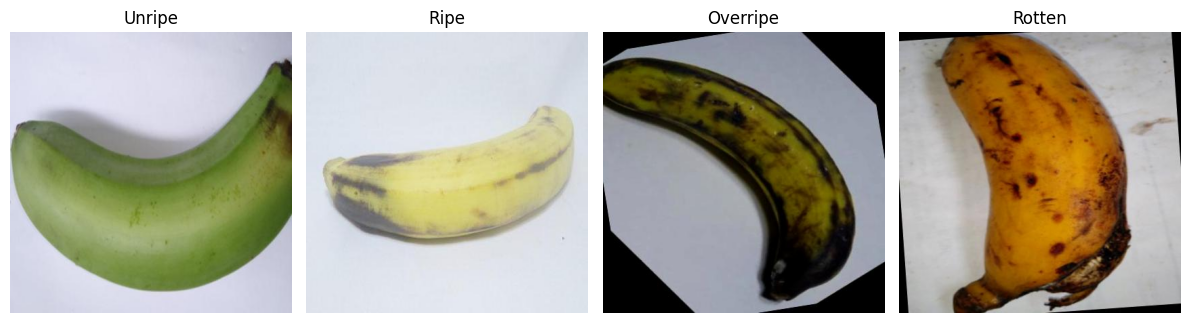

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

classes = ["unripe", "ripe", "overripe", "rotten"]

plt.figure(figsize=(12, 4))

for i, class_name in enumerate(classes):
    folder = root / "train" / class_name

    images = [
        p for p in folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
    ]

    image = Image.open(images[0]).convert("RGB")

    plt.subplot(1, 4, i + 1)
    plt.imshow(image)
    plt.title(class_name.capitalize())
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    root / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    root / "valid",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    root / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Found 11793 files belonging to 4 classes.
Found 1123 files belonging to 4 classes.
Found 562 files belonging to 4 classes.
Classes: ['overripe', 'ripe', 'rotten', 'unripe']
Number of classes: 4


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Dataset is ready for training!")

Dataset is ready for training!


In [ ]:
from tensorflow.keras import layers, Model

# โหลด MobileNetV2 ที่ผ่านการฝึกด้วย ImageNet
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze น้ำหนักของ MobileNetV2
base_model.trainable = False

# เพิ่ม Data Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
])

# สร้างโมเดล
inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# ปรับค่าพิกเซลให้เหมาะกับ MobileNetV2
x = layers.Rescaling(1./127.5, offset=-1)(x)

# ใช้ MobileNetV2 สกัดคุณลักษณะ
x = base_model(x, training=False)

# เพิ่มชั้นสำหรับจำแนกประเภท
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(4, activation="softmax")(x)

model = Model(inputs, outputs)

# Compile โมเดล
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# แสดงโครงสร้างโมเดล
model.summary()

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "banana_mobilenetv2_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
369/369 ━━━━━━━━━━━━━━━━━━━━ 722s 2s/step - accuracy: 0.8674 - loss: 0.3564 - val_accuracy: 0.9519 - val_loss: 0.1604
Epoch 2/10
369/369 ━━━━━━━━━━━━━━━━━━━━ 746s 2s/step - accuracy: 0.9364 - loss: 0.1827 - val_accuracy: 0.9581 - val_loss: 0.1417
Epoch 3/10
369/369 ━━━━━━━━━━━━━━━━━━━━ 773s 2s/step - accuracy: 0.9456 - loss: 0.1615 - val_accuracy: 0.9662 - val_loss: 0.1205
Epoch 4/10
369/369 ━━━━━━━━━━━━━━━━━━━━ 752s 2s/step - accuracy: 0.9477 - loss: 0.1523 - val_accuracy: 0.9671 - val_loss: 0.1139
Epoch 5/10
369/369 ━━━━━━━━━━━━━━━━━━━━ 752s 2s/step - accuracy: 0.9497 - loss: 0.1424 - val_accuracy: 0.9671 - val_loss: 0.1083
Epoch 6/10
369/369 ━━━━━━━━━━━━━━━━━━━━ 751s 2s/step - accuracy: 0.9541 - loss: 0.1354 - val_accuracy: 0.9662 - val_loss: 0.1135
Epoch 7/10
369/369 ━━━━━━━━━━━━━━━━━━━━ 750s 2s/step - accuracy: 0.9541 - loss: 0.1335 - val_accuracy: 0.9715 - val_loss: 0.1039
Epoch 8/10
369/369 ━━━━━━━━━━━━━━━━━━━━ 748s 2s/step - accuracy: 0.9549 - loss: 0.1287 - val_accu